# Strategy 2 — Parameter-Tuned Adaptive Reasoner
**Topic:** LLM-based reasoning strategies in FrozenLake-v1 · **Platform:** Google Colab — **GPU T4**

**Focus: model parameters and sampling.** The prompt is fixed; only `temperature`, `top_p` and `max_new_tokens` change.

**Hypothesis:** exploration increases creativity but may reduce the success rate.

| | |
|---|---|
| Memory | none (optional: reward feedback of the last move) |
| Decoding | deterministic (`T = 0`) vs exploratory (`T = 0.9`, `top_p = 0.8`) |
| Compared | temperature, top_p, max_new_tokens, reward feedback |
| Repeats | 2 per map for greedy runs, 5 per map for every sampled run |

## 1. Setup
Model: **`Qwen/Qwen2.5-1.5B-Instruct`** (open weights, fits a T4 GPU).

In [1]:
%pip install -q "gymnasium>=1.0" "transformers>=4.45,<5" accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os
import re
import textwrap
import time
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import logging as hf_logging
from transformers import set_seed as hf_set_seed

hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

SEED = 42
hf_set_seed(SEED)                         # seeds random, numpy and torch
assert torch.cuda.is_available(), "No GPU: Runtime → Change runtime type → T4 GPU"
print("PyTorch", torch.__version__, "| gymnasium", gym.__version__, "| GPU:", torch.cuda.get_device_name(0))

PyTorch 2.14.1+cu130 | gymnasium 1.4.0 | GPU: Tesla T4


## 2. Model
- `temperature = 0` → greedy decoding (`do_sample=False`, deterministic).
- `temperature > 0` → sampling with `top_p`.

In [3]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, padding_side="left")   # left padding for batched generation
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to("cuda").eval()
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct: 1.54B parameters


In [4]:
from transformers import StoppingCriteria, StoppingCriteriaList

# A sequence stops as soon as it has written a complete "ACTION: <move>" line.
# Without this, the 1.5B model often keeps repeating "ACTION: ..." lines until max_new_tokens,
# and the parsed (last) action then depends on where the output was cut.
STOP_RE = re.compile(r"ACTION\s*\**\s*[:=]\s*[\*\[<\s]*(LEFT|DOWN|RIGHT|UP)\b[\]>\*]*[ \t]*\n", re.IGNORECASE)

class StopAfterAction(StoppingCriteria):
    def __init__(self, prompt_len, window=16):
        self.prompt_len, self.window = prompt_len, window
    def __call__(self, input_ids, scores, **kwargs):
        start = max(self.prompt_len, input_ids.shape[1] - self.window)
        tails = tokenizer.batch_decode(input_ids[:, start:], skip_special_tokens=True)
        return torch.tensor([bool(STOP_RE.search(t)) for t in tails], device=input_ids.device)

@torch.no_grad()
def generate(conversations, max_new_tokens=256, temperature=0.0, top_p=1.0, seed=SEED, batch_size=64):
    # Batch of chat conversations → one output (text, number of tokens, truncated) per conversation.
    # If a conversation ends with an assistant message, that message is a PREFILL: the model continues it
    # (e.g. "Let's think step by step." forces the reasoning to be written before the action).
    hf_set_seed(seed)
    prompts, prefills = [], []
    for c in conversations:
        prefill = c[-1]["content"] if c[-1]["role"] == "assistant" else ""
        msgs = c[:-1] if prefill else c
        prompts.append(tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + prefill)
        prefills.append(prefill)
    if temperature > 0:
        sampling = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=0)
    else:
        sampling = dict(do_sample=False)
    results = []
    for b in range(0, len(prompts), batch_size):
        enc = tokenizer(prompts[b:b + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        stop = StoppingCriteriaList([StopAfterAction(enc.input_ids.shape[1])])
        out = model.generate(**enc, max_new_tokens=max_new_tokens, repetition_penalty=1.0, stopping_criteria=stop,
                             pad_token_id=tokenizer.pad_token_id, **sampling)
        for g, prefill in zip(out[:, enc.input_ids.shape[1]:], prefills[b:b + batch_size]):
            ids = g[g != tokenizer.pad_token_id].tolist()
            text = tokenizer.decode(ids, skip_special_tokens=True)
            results.append({"text": (prefill + text).strip(), "n_tokens": len(ids),
                            "truncated": len(ids) >= max_new_tokens})
    return results

print(generate([[{"role": "user", "content": "In one sentence: what is the FrozenLake environment?"}]], max_new_tokens=60)[0]["text"])

The FrozenLake environment is a reinforcement learning benchmark that simulates a frozen lake environment, allowing researchers to test and compare the performance of different reinforcement learning algorithms.


## 3. FrozenLake environment
`is_slippery=False`. Each run uses **10 maps** (the default 4x4 map + 9 random maps with fixed seeds), so the results do not depend on a single map. In every map S is the top-left corner and G the bottom-right corner. The LLM sees the grid with the agent marked **A**.

In [5]:
N_MAPS = 10
MAX_STEPS = 15     # step limit per episode

DEFAULT_MAP = ["SFFF", "FHFH", "FFFH", "HFFG"]
MAPS, seed = [{"id": "default", "desc": DEFAULT_MAP}], 0
while len(MAPS) < N_MAPS:                     # random maps without duplicates
    seed += 1
    desc = generate_random_map(size=4, p=0.7, seed=seed)
    if desc not in [m["desc"] for m in MAPS]:
        MAPS.append({"id": f"rand{seed}", "desc": desc})
MAP_BY_ID = {m["id"]: m for m in MAPS}
GOAL = (3, 3)

ACTIONS = ["LEFT", "DOWN", "RIGHT", "UP"]           # Gymnasium order: 0, 1, 2, 3
MOVES = [(0, -1), (1, 0), (0, 1), (-1, 0)]
TILE_NAMES = {"S": "the starting square (solid ice)", "F": "solid ice", "H": "a HOLE, you would fall in", "G": "the GOAL"}

def target(desc, pos, a):
    # Cell reached by action a (moving into the border leaves the agent in place).
    r, c = pos[0] + MOVES[a][0], pos[1] + MOVES[a][1]
    return (r, c) if 0 <= r < len(desc) and 0 <= c < len(desc) else pos

def goal_distances(desc):
    # BFS from G (only for evaluation): minimum steps from every cell to the goal.
    dist, queue = {GOAL: 0}, deque([GOAL])
    while queue:
        cur = queue.popleft()
        for a in range(4):
            nxt = target(desc, cur, a)
            if nxt not in dist and desc[nxt[0]][nxt[1]] != "H":
                dist[nxt] = dist[cur] + 1
                queue.append(nxt)
    return dist

def state_text(desc, pos=None):
    # The lake as text. With pos, the agent is marked A and its position is described.
    rows = [list(row) for row in desc]
    if pos is not None:
        rows[pos[0]][pos[1]] = "A"
    grid = "\n".join(["    c0 c1 c2 c3"] + [f"r{r}  " + "  ".join(row) for r, row in enumerate(rows)])
    if pos is None:
        return grid
    return (f"Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):\n"
            f"{grid}\nYou're on row {pos[0]}, col {pos[1]}, and the goal is on row {GOAL[0]}, col {GOAL[1]}.")

def neighbors_text(desc, pos):
    lines = []
    for a, name in enumerate(ACTIONS):
        nxt = target(desc, pos, a)
        if nxt == pos:
            lines.append(f"- {name}: that's the edge of the lake, you'd stay where you are")
        else:
            lines.append(f"- {name}: you'd land on row {nxt[0]}, col {nxt[1]}, which is {TILE_NAMES[desc[nxt[0]][nxt[1]]]}")
    return "\n".join(lines)

for m in MAPS:
    print(f"{m['id']:8s}", " | ".join(m["desc"]))
print("\n" + state_text(DEFAULT_MAP, (1, 0)))

default  SFFF | FHFH | FFFH | HFFG
rand1    SFFF | HFFH | HHFF | FHFG
rand2    SFHF | FHFF | FFFF | FFFG
rand3    SFHF | FFFF | HFFF | FFHG
rand4    SFFH | FFFF | FHFF | FFFG
rand5    SHFF | FFFF | FHFF | FHHG
rand6    SFHF | FFFF | HFFH | FFFG
rand7    SHFH | FFFF | FFFH | FFFG
rand8    SFFF | HFFF | FFFF | FFFG
rand9    SFFF | HFHF | HFFF | HFFG

Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  S  F  F  F
r1  A  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 1, col 0, and the goal is on row 3, col 3.


## 4. Action parser
The model must end with `ACTION: <LEFT|DOWN|RIGHT|UP>`. If no valid action is found, the step is a **parse failure**: the agent stays in place (no random fallback action, so every success comes from the model's own decision).

In [6]:
ACTION_TAG = re.compile(r"\bACTION\s*\**\s*[:=]\s*[\*\[<\s]*(LEFT|DOWN|RIGHT|UP)\b", re.IGNORECASE)
ACTION_WORD = re.compile(r"\b(LEFT|DOWN|RIGHT|UP)\b", re.IGNORECASE)

def parse_action(text):
    tags = ACTION_TAG.findall(text)                      # last 'ACTION:' tag
    if tags:
        return ACTIONS.index(tags[-1].upper())
    words = {w.upper() for w in ACTION_WORD.findall(text)}
    return ACTIONS.index(words.pop()) if len(words) == 1 else None   # or a single action word

for t in ["ACTION: RIGHT", "UP hits a hole, so I go RIGHT.\nACTION: <RIGHT>", "RIGHT", "UP would hit a hole, DOWN is safe"]:
    a = parse_action(t)
    print(f"{t!r:55} → {ACTIONS[a] if a is not None else None}")

'ACTION: RIGHT'                                         → RIGHT
'UP hits a hole, so I go RIGHT.\nACTION: <RIGHT>'       → RIGHT
'RIGHT'                                                 → RIGHT
'UP would hit a hole, DOWN is safe'                     → None


## 5. Agent loop and metrics
```
state → prompt → LLM → text → parser → action → env.step → new state  (until G, H or MAX_STEPS)
```
All episodes of a run advance together (one LLM batch per step). Figures are saved in `figures/` (PDF + PNG).

| Metric | Meaning |
|---|---|
| success rate | episodes that reach G |
| hole / timeout rate | episodes that fall into H / reach `MAX_STEPS` |
| steps (success) | mean steps of the successful episodes |
| optimal-move rate | steps that get closer to G along the shortest path |
| parse-fail rate | steps without a valid action |
| wall-bump rate | actions into the border |
| truncation rate | steps where the output hit `max_new_tokens` before an action line |
| tokens/step | generated tokens per decision (cost of the reasoning) |
| consistency | share of the repeats of a map that follow the most common path (reproducibility; needs ≥ 2 repeats, otherwise NaN) |
| episodes | number of episodes behind each rate (10 maps × repeats) — use it for confidence intervals |

Every configuration — deterministic or not — is run with **at least 2 repeats per map**, so consistency is measured, not assumed. With `temperature = 0` the 2 repeats should be identical; a value below 1 would reveal numerical non-determinism of batched fp16 generation.

In [7]:
def llm_decide(episodes, build_messages, gen_cfg, seed):
    outs = generate([build_messages(e) for e in episodes], seed=seed, **gen_cfg)
    return [{"text": o["text"], "n_tokens": o["n_tokens"], "action": parse_action(o["text"]),
             "extra": {"truncated": o["truncated"]}} for o in outs]

def run_episodes(maps, build_messages, gen_cfg, n_repeats=1, decide=llm_decide, label=""):
    episodes = []
    for m in maps:
        for rep in range(n_repeats):
            env = gym.make("FrozenLake-v1", desc=m["desc"], is_slippery=False)
            env.reset(seed=SEED)
            episodes.append({"map": m["id"], "desc": m["desc"], "rep": rep, "env": env, "pos": (0, 0),
                             "dist": goal_distances(m["desc"]), "trace": [], "done": False, "outcome": "timeout"})
    t0 = time.time()
    for step in range(MAX_STEPS):
        active = [e for e in episodes if not e["done"]]
        if not active:
            break
        for e, d in zip(active, decide(active, build_messages, gen_cfg, SEED + step)):
            pos, a = e["pos"], d["action"]
            if a is None:                              # parse failure: stay in place
                nxt, terminated = pos, False
            else:
                obs, _, terminated, _, _ = e["env"].step(a)
                nxt = divmod(int(obs), len(e["desc"]))
            tile = e["desc"][nxt[0]][nxt[1]]
            e["trace"].append({"step": step, "pos": pos, "action": None if a is None else ACTIONS[a], "next": nxt,
                               "tile": tile, "text": d["text"], "n_tokens": d["n_tokens"], "parse_fail": a is None,
                               "wall": a is not None and nxt == pos,
                               "optimal": e["dist"].get(nxt, -1) == e["dist"][pos] - 1, **d.get("extra", {})})
            e["pos"] = nxt
            if terminated:
                e["done"], e["outcome"] = True, ("goal" if tile == "G" else "hole")
    eps = pd.DataFrame([{"run": label, "map": e["map"], "rep": e["rep"], "outcome": e["outcome"],
                         "success": e["outcome"] == "goal", "steps": len(e["trace"]),
                         "path": "".join(t["action"][0] if t["action"] else "?" for t in e["trace"])} for e in episodes])
    steps = pd.DataFrame([{"run": label, "map": e["map"], "rep": e["rep"], **t} for e in episodes for t in e["trace"]])
    eps.attrs["seconds"] = time.time() - t0
    return eps, steps

In [8]:
def summary_table(runs):
    rows = {}
    for name, (eps, steps) in runs.items():
        succ = eps[eps["success"]]
        n_reps = eps.groupby("map")["rep"].nunique().min()   # consistency needs >= 2 repeats per map
        rows[name] = {
            "episodes": len(eps),
            "success rate": eps["success"].mean(),
            "hole rate": (eps["outcome"] == "hole").mean(),
            "timeout rate": (eps["outcome"] == "timeout").mean(),
            "steps (success)": succ["steps"].mean() if len(succ) else np.nan,
            "optimal-move rate": steps["optimal"].mean(),
            "parse-fail rate": steps["parse_fail"].mean(),
            "wall-bump rate": steps["wall"].mean(),
            "tokens/step": steps["n_tokens"].mean(),
            "truncation rate": steps["truncated"].mean() if "truncated" in steps else np.nan,
            "consistency": (eps.groupby("map")["path"].agg(lambda p: p.value_counts().iloc[0] / len(p)).mean()
                            if n_reps > 1 else np.nan),
            "seconds": eps.attrs.get("seconds", np.nan),
        }
    return pd.DataFrame(rows).T.astype(float).round(3)

os.makedirs("figures", exist_ok=True)

def plot_results(summary, title="", name=None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.4 * len(summary) + 2.2))
    summary[["success rate", "hole rate", "timeout rate"]].plot.barh(
        stacked=True, ax=axes[0], color=["tab:green", "tab:red", "tab:gray"])
    summary[["optimal-move rate", "parse-fail rate", "wall-bump rate"]].plot.barh(
        ax=axes[1], color=["tab:blue", "tab:orange", "tab:purple"])
    for ax, subtitle in zip(axes, ["Episode outcome", "Step-level decisions"]):
        ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(alpha=0.3, axis="x"); ax.set_title(subtitle); ax.legend(fontsize=8)
    axes[1].set_yticklabels([])
    fig.suptitle(title); plt.tight_layout()
    if name:                                   # PDF (vector, for LaTeX) + PNG (300 dpi)
        fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
        fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def show_transcript(steps, map_id, rep=0, max_chars=700):
    s = steps[(steps["map"] == map_id) & (steps["rep"] == rep)]
    print(state_text(MAP_BY_ID[map_id]["desc"], s["pos"].iloc[0]), "\n")
    for _, t in s.iterrows():
        print(f"━━━ step {t['step']} | {t['pos']} → {t['action']} → {t['next']} ({t['tile']}) | {t['n_tokens']} tokens ━━━")
        print(textwrap.indent(t["text"][:max_chars] + (" [...]" if len(t["text"]) > max_chars else ""), "  "), "\n")

## 6. Prompt and configurations
Prompt: the `rules` prompt of Strategy 1, **including its chain-of-thought prefill** (`Let's think step by step.`), so that every configuration actually writes reasoning before the action and the sampling parameters act on that reasoning. With this prompt, `deterministic` here is the same configuration as `rules` in Strategy 1 (sanity check: the numbers should match).

FrozenLake only gives +1 at G, so the optional **reward feedback** is written in the prompt (the environment reward does not change):

| Last move | Feedback |
|---|---|
| safe and closer to G | +1 |
| safe, not closer | 0 |
| into the wall / no valid action | −1 |

In [9]:
TASK = "You need to reach the goal (G) without falling into any hole (H). You can move LEFT, RIGHT, UP or DOWN."
FORMAT = "Once you've made up your mind, finish with one last line that says ACTION: followed by your move."
RULES = """A few things to keep in mind:
- UP takes you one row up (row - 1) and DOWN one row down (row + 1); LEFT and RIGHT move you one column (col - 1 / col + 1).
- If you try to walk off the edge of the lake, you just stay where you are.
- Stepping on a hole means you fall in and it's game over. Reaching G means you made it.
- Whenever you can, pick a move that brings you closer to G."""

T_BASE = """You're crossing a frozen lake, so you have to be careful where you step.
{state}
{task}
{rules}
Before deciding, go through each move: which square would it take you to, and is that square safe? Then go with the safest move that gets you closer to G.
{format}"""

T_FEEDBACK = """You're crossing a frozen lake, so you have to be careful where you step.
{state}
{task}
{rules}
How your last move went: {feedback}
Before deciding, go through each move: which square would it take you to, and is that square safe? Then go with the safest move that gets you closer to G.
{format}"""

def feedback_text(e):
    # Shaped reward of every move so far: +1 safe and closer to G (Manhattan distance), 0 safe, -1 edge / no valid move.
    if not e["trace"]:
        return "this is your first move, so nothing yet."
    dist = lambda p: abs(GOAL[0] - p[0]) + abs(GOAL[1] - p[1])
    rewards = [-1 if t["parse_fail"] or t["wall"] else int(dist(t["next"]) < dist(t["pos"])) for t in e["trace"]]
    t, r = e["trace"][-1], rewards[-1]
    if t["parse_fail"]:
        msg = "I couldn't tell which move you picked, so you stayed put"
    elif t["wall"]:
        msg = f"you went {t['action']} but bumped into the edge and stayed where you were"
    elif r > 0:
        msg = f"you went {t['action']} and got safely closer to the goal, nice"
    else:
        msg = f"you went {t['action']}; it was safe, but it didn't get you any closer to the goal"
    return f"{msg}. That's {r:+d} for that move ({sum(rewards):+d} so far)."

COT_PREFILL = "Let's think step by step.\n"         # same prefill as the `rules` prompt of Strategy 1

def build_prompt(e, feedback=False):
    template, fb = (T_FEEDBACK, feedback_text(e)) if feedback else (T_BASE, "")
    return [{"role": "user", "content": template.format(
                state=state_text(e["desc"], e["pos"]), task=TASK, rules=RULES, format=FORMAT, feedback=fb)},
            {"role": "assistant", "content": COT_PREFILL}]

N_REPEATS = 5                                         # repeats per map for EVERY sampled configuration
N_DET_REPEATS = 2                                     # repeats per map for greedy configurations
DETERMINISTIC = dict(temperature=0.0, max_new_tokens=256)
EXPLORATORY = dict(temperature=0.9, top_p=0.8, max_new_tokens=256)

for m in build_prompt({"desc": DEFAULT_MAP, "pos": (0, 0), "trace": []}):
    print(f"[{m['role']}]\n{m['content']}")

[user]
You're crossing a frozen lake, so you have to be careful where you step.
Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  A  F  F  F
r1  F  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 0, col 0, and the goal is on row 3, col 3.
You need to reach the goal (G) without falling into any hole (H). You can move LEFT, RIGHT, UP or DOWN.
A few things to keep in mind:
- UP takes you one row up (row - 1) and DOWN one row down (row + 1); LEFT and RIGHT move you one column (col - 1 / col + 1).
- If you try to walk off the edge of the lake, you just stay where you are.
- Stepping on a hole means you fall in and it's game over. Reaching G means you made it.
- Whenever you can, pick a move that brings you closer to G.
Before deciding, go through each move: which square would it take you to, and is that square safe? Then go with the safest move that gets you closer to G.
Once you've made up your mind, finish with one l

## 7. Experiments
Greedy decoding is deterministic, so `N_DET_REPEATS = 2` repeats are enough to check it; **all** sampled configurations use the same `N_REPEATS = 5`, so their success rates and consistencies are directly comparable.

In [10]:
# Deterministic vs exploratory
runs = {}
runs["deterministic"] = run_episodes(MAPS, build_prompt, DETERMINISTIC, n_repeats=N_DET_REPEATS, label="deterministic")
runs["exploratory"] = run_episodes(MAPS, build_prompt, EXPLORATORY, n_repeats=N_REPEATS, label="exploratory")
display(summary_table(runs))

,episodes,success rate,hole rate,timeout rate,steps (success),optimal-move rate,parse-fail rate,wall-bump rate,tokens/step,truncation rate,consistency,seconds
deterministic,20.0,0.0,0.30,0.70,NaN,0.091,0.773,0.100,224.482,0.682,1.00,163.912
exploratory,50.0,0.0,0.82,0.18,NaN,0.271,0.292,0.207,168.920,0.305,0.22,205.714


In [11]:
# Temperature and top_p (T=0 and T=0.9/top_p=0.8 come from the previous cell)
for T, p in [(0.3, 0.8), (0.6, 0.8), (1.2, 0.8), (0.9, 1.0)]:
    name = f"T={T}, top_p={p}"
    runs[name] = run_episodes(MAPS, build_prompt, dict(temperature=T, top_p=p, max_new_tokens=256), n_repeats=N_REPEATS, label=name)
    print(f"done: {name} ({runs[name][0].attrs['seconds']:.0f} s)")

done: T=0.3, top_p=0.8 (214 s)
done: T=0.6, top_p=0.8 (213 s)
done: T=1.2, top_p=0.8 (203 s)
done: T=0.9, top_p=1.0 (183 s)


In [12]:
# Token budget (256 = "deterministic")
for B in [64, 128, 512]:
    name = f"max_new_tokens={B}"
    runs[name] = run_episodes(MAPS, build_prompt, dict(temperature=0.0, max_new_tokens=B), n_repeats=N_DET_REPEATS, label=name)
    print(f"done: {name} ({runs[name][0].attrs['seconds']:.0f} s)")

done: max_new_tokens=64 (56 s)
done: max_new_tokens=128 (93 s)
done: max_new_tokens=512 (295 s)


In [13]:
# Reward feedback in the prompt
with_feedback = lambda e: build_prompt(e, feedback=True)
runs["deterministic + feedback"] = run_episodes(MAPS, with_feedback, DETERMINISTIC, n_repeats=N_DET_REPEATS, label="deterministic + feedback")
runs["exploratory + feedback"] = run_episodes(MAPS, with_feedback, EXPLORATORY, n_repeats=N_REPEATS, label="exploratory + feedback")

## 8. Results

,episodes,success rate,hole rate,timeout rate,steps (success),optimal-move rate,parse-fail rate,wall-bump rate,tokens/step,truncation rate,consistency,seconds
deterministic,20.0,0.00,0.30,0.70,NaN,0.091,0.773,0.100,224.482,0.682,1.00,163.912
exploratory,50.0,0.00,0.82,0.18,NaN,0.271,0.292,0.207,168.920,0.305,0.22,205.714
"T=0.3, top_p=0.8",50.0,0.00,0.70,0.30,NaN,0.255,0.228,0.321,146.042,0.230,0.26,213.858
"T=0.6, top_p=0.8",50.0,0.06,0.68,0.26,12.333,0.311,0.278,0.190,157.534,0.276,0.26,213.338
"T=1.2, top_p=0.8",50.0,0.02,0.84,0.14,11.000,0.251,0.296,0.237,163.821,0.259,0.20,203.414
"T=0.9, top_p=1.0",50.0,0.02,0.84,0.14,11.000,0.245,0.329,0.198,163.493,0.245,0.24,183.038
max_new_tokens=64,20.0,0.00,0.10,0.90,NaN,0.096,0.699,0.176,63.037,0.787,1.00,55.742
max_new_tokens=128,20.0,0.00,0.10,0.90,NaN,0.066,0.919,0.000,126.463,0.978,1.00,92.926
max_new_tokens=512,20.0,0.00,0.30,0.70,NaN,0.091,0.773,0.100,387.436,0.636,1.00,294.943
deterministic + feedback,20.0,0.10,0.60,0.30,12.000,0.338,0.059,0.353,125.985,0.088,1.00,133.500


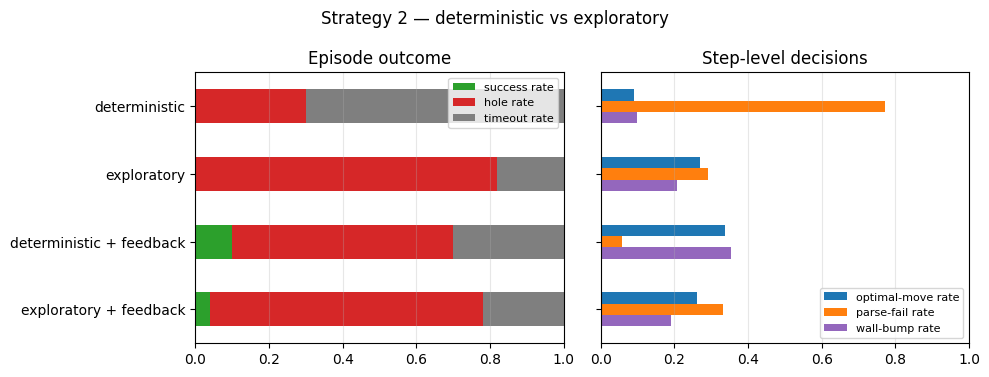

In [14]:
summary = summary_table(runs)
display(summary)
plot_results(summary.loc[["deterministic", "exploratory", "deterministic + feedback", "exploratory + feedback"]],
             "Strategy 2 — deterministic vs exploratory", name="s2_deterministic_vs_exploratory")

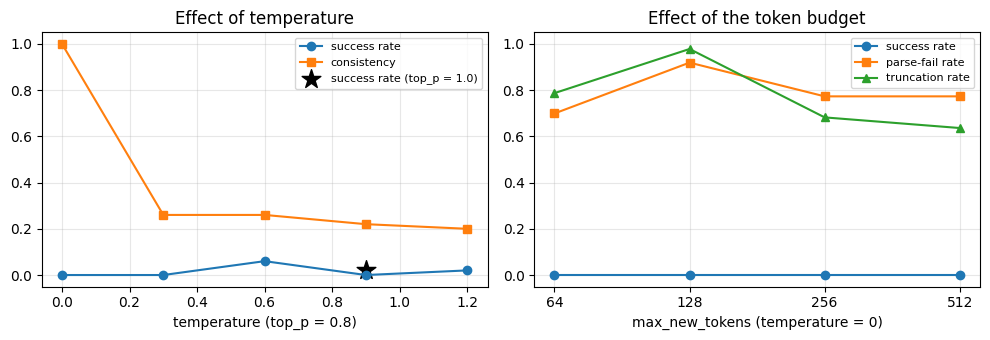

In [15]:
temps = {0.0: "deterministic", 0.3: "T=0.3, top_p=0.8", 0.6: "T=0.6, top_p=0.8", 0.9: "exploratory", 1.2: "T=1.2, top_p=0.8"}
budgets = {64: "max_new_tokens=64", 128: "max_new_tokens=128", 256: "deterministic", 512: "max_new_tokens=512"}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for col, mk in [("success rate", "o"), ("consistency", "s")]:
    axes[0].plot(list(temps), summary.loc[list(temps.values()), col], marker=mk, label=col)
axes[0].scatter([0.9], [summary.loc["T=0.9, top_p=1.0", "success rate"]], marker="*", s=200, color="black",
                label="success rate (top_p = 1.0)")
axes[0].set_xlabel("temperature (top_p = 0.8)"); axes[0].set_title("Effect of temperature")
for col, mk in [("success rate", "o"), ("parse-fail rate", "s"), ("truncation rate", "^")]:
    axes[1].plot(list(budgets), summary.loc[list(budgets.values()), col], marker=mk, label=col)
axes[1].set_xscale("log", base=2); axes[1].set_xticks(list(budgets)); axes[1].set_xticklabels(list(budgets))
axes[1].set_xlabel("max_new_tokens (temperature = 0)"); axes[1].set_title("Effect of the token budget")
for ax in axes:
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig("figures/s2_temperature_and_budget.pdf", bbox_inches="tight")
fig.savefig("figures/s2_temperature_and_budget.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Reasoning transcripts
Same map, deterministic vs exploratory.

In [16]:
SHOW_MAP = "default"
for name in ["deterministic", "exploratory"]:
    print(f"\n████████ {name} ████████")
    show_transcript(runs[name][1], SHOW_MAP, rep=0, max_chars=500)


████████ deterministic ████████
Here is the lake right now (A is you, S is the start, F is solid ice, H is a hole, G is the goal):
    c0 c1 c2 c3
r0  A  F  F  F
r1  F  H  F  H
r2  F  F  F  H
r3  H  F  F  G
You're on row 0, col 0, and the goal is on row 3, col 3. 

━━━ step 0 | (0, 0) → RIGHT → (0, 1) (F) | 256 tokens ━━━
  Let's think step by step.
  1. I'm currently on row 0, col 0.
  2. The goal is on row 3, col 3.
  3. The safest move is to move RIGHT to row 0, col 1.
  4. This move takes me to a solid ice square (F), which is safe.
  5. The next move is to move RIGHT again to row 0, col 2.
  6. This move takes me to a solid ice square (F), which is safe.
  7. The next move is to move RIGHT again to row 0, col 3.
  8. This move takes me to a solid ice square (F), which is safe.
  9. The next move is to move RIGHT again to row 1, [...] 

━━━ step 1 | (0, 1) → None → (0, 1) (F) | 256 tokens ━━━
  Let's think step by step.
  1. You are currently on row 0, col 1.
  2. The goal is on r

## 10. Save results
`summary_s2.csv` and `steps_s2.csv` are read by `Strategy_Comparison.ipynb`.

In [17]:
summary.assign(strategy="S2").to_csv("summary_s2.csv")
pd.concat([steps for _, steps in runs.values()]).to_csv("steps_s2.csv", index=False)
print("saved: summary_s2.csv, steps_s2.csv")

saved: summary_s2.csv, steps_s2.csv


In [18]:
# Download the results (Colab only). Upload them to results/ in the repo for the comparison notebook.
import zipfile
try:
    from google.colab import files
except ImportError:
    files = None

with zipfile.ZipFile("experiment_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for filename in ['summary_s2.csv', 'steps_s2.csv']:
        if os.path.exists(filename):
            z.write(filename)
    for root, _, filenames in os.walk("figures"):
        for filename in filenames:
            z.write(os.path.join(root, filename))
print("zip:", "experiment_results.zip")
if files is not None:
    files.download("experiment_results.zip")

zip: experiment_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>